In [3]:
%cd D:/ML/Assignment

D:\ML\Assignment


In [ ]:
# Machine Learning Assignment
## Classification Algorithms on Iris Dataset

### Dataset:
Iris Dataset downloaded from Kaggle database

### Objective:
To apply different machine learning classification algorithms
and compare their performance.

In [5]:
#Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [9]:
#Set path and load dataset
DATA_PATH = "D:/ML/Assignment/iris.csv.csv"

df = pd.read_csv(DATA_PATH)

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,class
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [10]:
#Check dataset
print("Dataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

Dataset shape:
(150, 6)

Column names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'target', 'class']

First 5 rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,class
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   class              150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [12]:
#Check missing values
print("Missing values in each column:")
print(df.isnull().sum())
print("Total missing values:", df.isnull().sum().sum())
df.describe()      #Basic statistics

Missing values in each column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
class                0
dtype: int64
Total missing values: 0


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [27]:
# Check target/classes
print(df["class"].value_counts())

class
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [28]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,class
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [29]:
# Separate features and target

X = df.drop(["target", "class"], axis=1)
y = df["class"]

print("Features:")
display(X.head())

print("\nTarget:")
display(y.head())

Features:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Target:


0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: class, dtype: object

In [30]:
#Encode target labels
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Original classes:")
print(label_encoder.classes_)

print("\nEncoded classes:")
print(y_encoded[:10])

Original classes:
['setosa' 'versicolor' 'virginica']

Encoded classes:
[0 0 0 0 0 0 0 0 0 0]


In [31]:
#Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.25,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 112
Testing samples: 38


In [32]:
#Feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data after scaling:")
print(X_train_scaled[:5])

Training data after scaling:
[[ 1.79213839 -0.60238047  1.31532306  0.92095427]
 [ 2.14531053 -0.60238047  1.65320421  1.05135487]
 [-0.4446185  -1.50797259 -0.03620155 -0.25265117]
 [ 0.26172578 -0.60238047  0.13273902  0.13855064]
 [-0.4446185  -1.28157456  0.13273902  0.13855064]]


In [33]:
# 1. Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train_scaled, y_train)

logistic_predictions = logistic_model.predict(X_test_scaled)

logistic_accuracy = accuracy_score(
    y_test,
    logistic_predictions
)

print("Logistic Regression Accuracy:",
      round(logistic_accuracy, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    logistic_predictions,
    target_names=label_encoder.classes_
))

Logistic Regression Accuracy: 0.9211

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.86      0.92      0.89        13
   virginica       0.92      0.85      0.88        13

    accuracy                           0.92        38
   macro avg       0.92      0.92      0.92        38
weighted avg       0.92      0.92      0.92        38



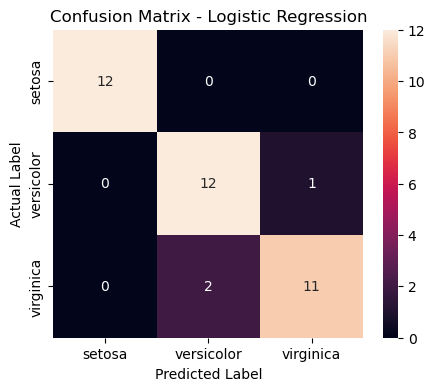

In [34]:
# Logistic Regression Confusion Matrix
cm = confusion_matrix(
    y_test,
    logistic_predictions
)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [35]:
# 2. SVM
from sklearn.svm import SVC

svm_model = SVC()

svm_model.fit(X_train_scaled, y_train)

svm_predictions = svm_model.predict(X_test_scaled)

svm_accuracy = accuracy_score(
    y_test,
    svm_predictions
)

print("SVM Accuracy:",
      round(svm_accuracy, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    svm_predictions,
    target_names=label_encoder.classes_
))

SVM Accuracy: 0.9474

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.92      0.92      0.92        13
   virginica       0.92      0.92      0.92        13

    accuracy                           0.95        38
   macro avg       0.95      0.95      0.95        38
weighted avg       0.95      0.95      0.95        38



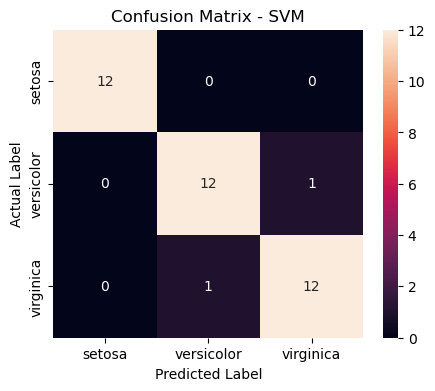

In [36]:
# SVM Confusion Matrix
cm = confusion_matrix(
    y_test,
    svm_predictions
)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Confusion Matrix - SVM")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [37]:
# 3. Naive Bayes
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()

nb_model.fit(X_train_scaled, y_train)

nb_predictions = nb_model.predict(X_test_scaled)

nb_accuracy = accuracy_score(
    y_test,
    nb_predictions
)

print("Naive Bayes Accuracy:",
      round(nb_accuracy, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    nb_predictions,
    target_names=label_encoder.classes_
))

Naive Bayes Accuracy: 0.9211

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.86      0.92      0.89        13
   virginica       0.92      0.85      0.88        13

    accuracy                           0.92        38
   macro avg       0.92      0.92      0.92        38
weighted avg       0.92      0.92      0.92        38



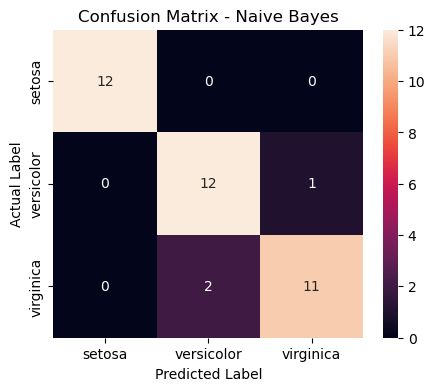

In [38]:
#Naive Bayes Confusion Matrix
cm = confusion_matrix(
    y_test,
    nb_predictions
)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Confusion Matrix - Naive Bayes")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [39]:
# 4. K-Nearest Neighbors
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

knn_predictions = knn_model.predict(X_test_scaled)

knn_accuracy = accuracy_score(
    y_test,
    knn_predictions
)

print("KNN Accuracy:",
      round(knn_accuracy, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    knn_predictions,
    target_names=label_encoder.classes_
))

KNN Accuracy: 0.9211

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.81      1.00      0.90        13
   virginica       1.00      0.77      0.87        13

    accuracy                           0.92        38
   macro avg       0.94      0.92      0.92        38
weighted avg       0.94      0.92      0.92        38



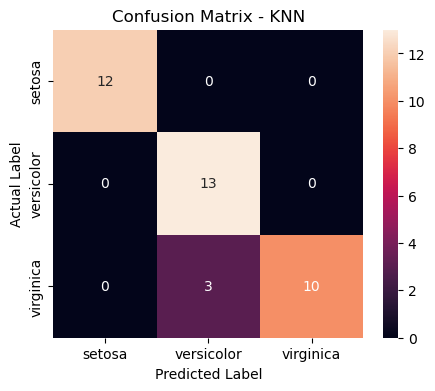

In [40]:
#KNN Confusion Matrix
cm = confusion_matrix(
    y_test,
    knn_predictions
)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Confusion Matrix - KNN")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [41]:
# 5. Decision Tree
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(X_train_scaled, y_train)

dt_predictions = dt_model.predict(X_test_scaled)

dt_accuracy = accuracy_score(
    y_test,
    dt_predictions
)

print("Decision Tree Accuracy:",
      round(dt_accuracy, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    dt_predictions,
    target_names=label_encoder.classes_
))

Decision Tree Accuracy: 0.8947

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.80      0.92      0.86        13
   virginica       0.91      0.77      0.83        13

    accuracy                           0.89        38
   macro avg       0.90      0.90      0.90        38
weighted avg       0.90      0.89      0.89        38



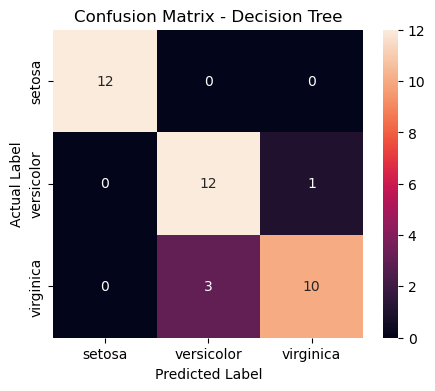

In [42]:
#Decision Tree Confusion Matrix
cm = confusion_matrix(
    y_test,
    dt_predictions
)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [43]:
# 6. Random Forest
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train_scaled, y_train)

rf_predictions = rf_model.predict(X_test_scaled)

rf_accuracy = accuracy_score(
    y_test,
    rf_predictions
)

print("Random Forest Accuracy:",
      round(rf_accuracy, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_predictions,
    target_names=label_encoder.classes_
))

Random Forest Accuracy: 0.9211

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.86      0.92      0.89        13
   virginica       0.92      0.85      0.88        13

    accuracy                           0.92        38
   macro avg       0.92      0.92      0.92        38
weighted avg       0.92      0.92      0.92        38



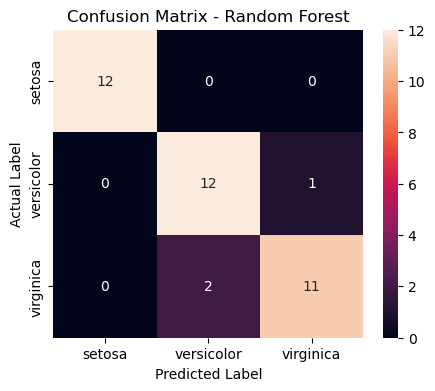

In [44]:
#Random Forest Confusion Matrix
cm = confusion_matrix(
    y_test,
    rf_predictions
)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [45]:
#Compare all six accuracies
results_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "SVM",
        "Naive Bayes",
        "KNN",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        logistic_accuracy,
        svm_accuracy,
        nb_accuracy,
        knn_accuracy,
        dt_accuracy,
        rf_accuracy
    ]
})

results_df["Accuracy"] = results_df["Accuracy"].round(4)

display(results_df)

,Model,Accuracy
0,Logistic Regression,0.9211
1,SVM,0.9474
2,Naive Bayes,0.9211
3,KNN,0.9211
4,Decision Tree,0.8947
5,Random Forest,0.9211


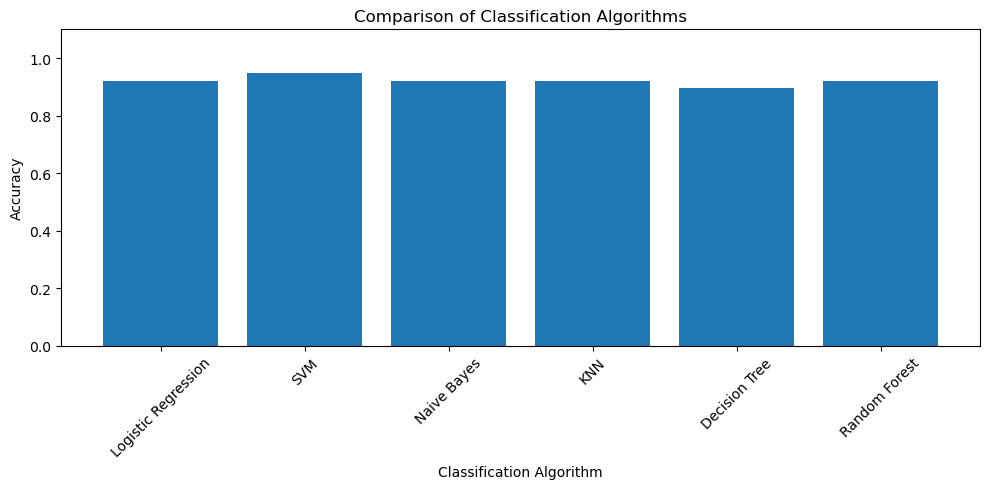

In [46]:
#Accuracy graph
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.xlabel("Classification Algorithm")
plt.ylabel("Accuracy")
plt.title("Comparison of Classification Algorithms")

plt.xticks(rotation=45)
plt.ylim(0, 1.1)

plt.tight_layout()
plt.show()

In [ ]:
## Conclusion

Six classification algorithms were applied to the Iris dataset:

1. Logistic Regression
2. Support Vector Machine (SVM)
3. Naive Bayes
4. K-Nearest Neighbors (KNN)
5. Decision Tree
6. Random Forest

The dataset was divided into training and testing sets, and the features
were standardized before model training. Each classification algorithm
was trained using the training data and evaluated on the test data.

The performance of the models was evaluated using accuracy and
classification reports. Confusion matrices were also generated to
visualize the correct and incorrect classification of the three Iris
species.

The accuracy comparison provides an overall view of the performance of
the six classification algorithms on the Iris dataset.